In [20]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.datasets import load_iris, load_wine, load_breast_cancer

In [10]:
#project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
#if project_root not in sys.path:
#    sys.path.append(project_root)

#print(" Project root added:", project_root)

In [11]:
# Get current working directory (notebook-safe)
PROJECT_ROOT = Path.cwd().parents[1]

# Add to Python path if not already there
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root added:", PROJECT_ROOT)

Project root added: c:\My_Files\Projects\AutoML_Drd


In [12]:
from core.metrics import evaluate_tree
from evolution.encode_decode import decode
from evolution.genetic_DT_GA import genetic_DT_GA

In [13]:
def eval_gene_on_dataset(gene, X, y, k=5, seed=123):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    scores = []
    for tr, te in skf.split(X, y):
        tree = decode(gene)
        m = evaluate_tree(tree, X[tr], y[tr], X[te], y[te])
        scores.append(m["f1"])
    return np.array(scores)

In [14]:
# ============================================================
# UCI Datasets
# ============================================================

@dataclass
class Source:
    # General Parsing Info
    url: str                
    sep: str                ## CSV Sep
    header: int = None      ## Header row number.
    nan_type: str = None    ## Which chars to replace with NaN

    # Specific split information
    id_col: int = None      ## ID column to remove it
    target_col: int = -1    ## On which column is the target
    one_hot: bool = False   ## Semeion has its target as one-hot

# Liste des datasets UCI utilisés dans HEAD-DT / MOHEAD-DT
UCI_DATASETS = {
    "abalone":              Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/abalone/abalone.data",
                                   sep=",",    nan_type=None),

    "anneal":               Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/annealing/anneal.data",
                                   sep=",",    nan_type="?"),

    "arrhythmia":           Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/arrhythmia/arrhythmia.data",
                                   sep=",",    nan_type="?"),

    "bridges-version1":     Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/bridges/bridges.data.version1",
                                   sep=",",    nan_type="?",   id_col=0),

    "car":                  Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/car/car.data",
                                   sep=",",    nan_type=None),

    #"cylinder-bands":       Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/cylinder-bands/bands.data",
    #                               sep=",",    nan_type="?"),

    "cylinder-bands":       Source(url=str(PROJECT_ROOT / "data" / "UCI" / "cylinder_bands.csv"),
                                   sep=",",    nan_type="?"),

    "glass":                Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data",
                                   sep=",",    nan_type=None,   id_col=0),

    "hepatitis":            Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/hepatitis/hepatitis.data",
                                   sep=",",    nan_type="?",   target_col=0),

    "iris":                 Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data",
                                   sep=",",    nan_type=None),

    "semeion":              Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/semeion/semeion.data",
                                   sep=r"\s+", nan_type=None,  one_hot=True),

    "shuttle_landing":      Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/shuttle-landing-control/shuttle-landing-control.data",
                                   sep=",",    nan_type="*",   target_col=0),

    "winequality-red":      Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
                                   sep=";",    header=0, nan_type=None),

    "winequality-white":    Source(url="https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
                                   sep=";",    header=0, nan_type=None),
    # ➕ Tu peux ajouter ici d'autres datasets de Table 1
}
# "audiology": "https://archive.ics.uci.edu/ml/machine-learning-databases/audiology/audiology.data",
# "segment": "https://archive.ics.uci.edu/ml/machine-learning-databases/image/segmentation.data",

In [15]:
# Function to read and prepare X, Y from the UCI datasets
def load_uci_dataset(source: Source):

    # Read CSV
    df = pd.read_csv(
        source.url,
        header=source.header,
        sep=source.sep,
        na_values=source.nan_type,
    )
    
    id_col = source.id_col
    target_col = source.target_col
    one_hot_encoding = source.one_hot

    # Special case: Semeion
    if one_hot_encoding:

        # Get Features
        X = df.iloc[:,:-10]

        # Last 10 cols are encoded as one-hot
        y_onehot = df.iloc[:,-10:]

        # Transform from one-hot into ordinal
        Y = np.argmax(y_onehot.to_numpy(), axis=1)

        # Encode target labels
        Y = LabelEncoder().fit_transform(Y.astype(str))
        return X, Y

    # --- Others ---
    # Remove ID
    if not(id_col is None):
        df = df.drop(df.columns[id_col], axis=1)
    
    # Split target & features
    target_col_name = df.columns[target_col]
    X = df.drop(target_col_name, axis=1)
    Y = df[target_col_name]

    # Encode target labels
    Y = LabelEncoder().fit_transform(Y.astype(str))

    return X, Y

In [35]:
# Build dataset list 
iris = load_iris(return_X_y=True)
wine = load_wine(return_X_y=True)
bc   = load_breast_cancer(return_X_y=True)
hepatitis = load_uci_dataset(UCI_DATASETS["hepatitis"])

datasets = [
    (iris[0], iris[1], "iris"),
    (wine[0], wine[1], "wine"),
    (bc[0],   bc[1],   "breast_cancer"),
    (hepatitis[0].to_numpy(), hepatitis[1], "hepatitis")
]

Starting Evolutionary Process...
Experiment with mu=10, lambda=10 for 10 generations.
Datasets to be trained on: ['iris', 'wine', 'breast_cancer', 'hepatitis']
Gen 0: best score = 0.7502, Execution time = 515.519 seconds.
Best Genome: [12, 1, 89, 3, 2, 1, 1, 27]
Gen 1: best score = 0.7502, Execution time = 978.2261 seconds.
Best Genome: [12, 1, 89, 3, 2, 1, 1, 27]
 Error during evaluation: division by zero
 Error during evaluation: division by zero
 Error during evaluation: division by zero
Gen 2: best score = 0.7600, Execution time = 502.2507 seconds.
Best Genome: [12, 2, 5, 3, 4, 0, 3, 0]
Gen 3: best score = 0.7600, Execution time = 541.4713 seconds.
Best Genome: [12, 2, 5, 3, 4, 0, 3, 0]
Gen 4: best score = 0.7723, Execution time = 693.1566 seconds.
Best Genome: [12, 1, 5, 3, 4, 0, 3, 4]
Gen 5: best score = 0.7791, Execution time = 610.9847 seconds.
Best Genome: [12, 2, 10, 3, 4, 0, 3, 4]
 Error during evaluation: free variable 'idx_left' referenced before assignment in enclosing sc

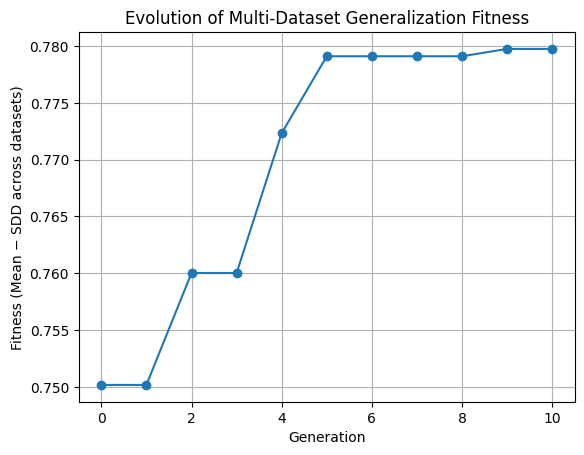

In [36]:
mu = 10
lambd = 10
generations = 10

print("Starting Evolutionary Process...")
print(f"Experiment with mu={mu}, lambda={lambd} for {generations} generations.")
print("Datasets to be trained on:", [e[-1] for e in datasets])

evo_t0 = time.time()
best_gene, best_fit, history = genetic_DT_GA(datasets, mu=mu, lambd=lambd, generations=generations)
evo_tf = time.time()

print("Total time (s):", round(evo_tf - evo_t0, 4))
print("Best gene:", best_gene)
print("Fitness (mean - SDD):", best_fit)

# Report generalization across datasets 
for X, y, name in datasets:
    scores = eval_gene_on_dataset(best_gene, X, y, k=5)
    print(f"{name}: mean F1={scores.mean():.4f}, std F1={scores.std():.4f}, folds={scores}")

plt.plot(history, marker="o")
plt.title("Evolution of Multi-Dataset Generalization Fitness")
plt.xlabel("Generation")
plt.ylabel("Fitness (Mean − SDD across datasets)")
plt.grid(True)
plt.show()